In [2]:
from ase.io import read
from ase.build import make_supercell
from matplotlib import rc

rc("text", usetex=True)
import matplotlib.pylab as pylab
from matplotlib import pyplot as plt

params = {"legend.fontsize": "14", "axes.labelsize": 20, "axes.titlesize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16}
pylab.rcParams.update(params)
import numpy as np
import glob

try:
    from tqdm import tqdm as _tqdm

    _TQDM_AVAILABLE = True
except ImportError:
    _TQDM_AVAILABLE = False


def _progress(iterable, **kwargs):
    """Wrap an iterable with tqdm if available, else return as-is."""
    if _TQDM_AVAILABLE:
        return _tqdm(iterable, **kwargs)
    return iterable

In [2]:
# load the molecular dynamics trajectory
traj_directory = "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_01/"
all_traj_files = glob.glob(traj_directory + "langevin_md_*.traj")
traj = []
for i in range(len(all_traj_files)):
    print(f"Loading trajectory file {i+1}/{len(all_traj_files)}: {all_traj_files[i]}")
    traj_name = traj_directory + f"langevin_md_{i+1}.traj"
    traj += read(traj_name, index=":")
print("loaded", len(traj), "frames")

# Now loop through the trajectory and computed the averaged position of each atom across the trajectory, taking into account the periodic boundary conditions, and make it into a new ASE Atoms object as the reference structure for the essential dynamics analysis.
averaged_structure = traj[0].copy()
for atom in averaged_structure:
    averaged_structure.positions[atom.index] = np.zeros(3)

for frame in _progress(traj, desc="Computing averaged structure", leave=False):
    for atom in frame:
        fractional_position = np.dot(atom.position, np.linalg.inv(frame.cell))
        fractional_position -= np.round(fractional_position)
        wrapped_position = np.dot(fractional_position, frame.cell)
        averaged_structure.positions[atom.index] += wrapped_position
averaged_structure.positions /= len(traj)
print("computed averaged structure")

Loading trajectory file 1/2: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_01/langevin_md_2.traj
Loading trajectory file 2/2: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_01/langevin_md_1.traj
loaded 100002 frames


computed averaged structure


In [3]:
# now loop through the trajectory, and for each frame, calculate the displacement of each atom from its position in the equilibrium structure, taking into account the periodic boundary conditions, and normalise the displacement by the square root of the mass of each atom.
atomic_displacements = []
system_energies = []


def compute_atomic_displacements(index, atom):
    ## Calculate displacement from equilibrium position
    ##delta_r = atom.position - equilibrium_structure[index].position

    # calculate displacement from averaged position
    delta_r = atom.position - averaged_structure[index].position
    # Apply periodic boundary conditions
    delta_r -= np.round(delta_r / frame.cell.diagonal()) * frame.cell.diagonal()
    # Normalise by square root of mass
    normalized_displacement = delta_r / np.sqrt(atom.mass)
    return normalized_displacement


for frame in _progress(traj, desc="Compute mass-normalized displacements", leave=False):
    atomic_displacements.append(np.array([compute_atomic_displacements(i, atom) for i, atom in enumerate(frame)]).reshape(-1))
    system_energies.append(frame.get_potential_energy() / frame.get_number_of_atoms())

Compute mass-normalized displacements:   0%|          | 0/100002 [00:00<?, ?it/s]/var/folders/br/04zcp1g56w37cwn0tggh9fjw0000gn/T/ipykernel_69115/4109826831.py:21: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  system_energies.append(frame.get_potential_energy() / frame.get_number_of_atoms())


In [ ]:
covariance_matrix = np.zeros((averaged_structure.get_number_of_atoms() * 3, averaged_structure.get_number_of_atoms() * 3))
atomic_displacements = np.array(atomic_displacements)

for i in _progress(range(averaged_structure.get_number_of_atoms() * 3), desc="Compute covariance matrix", leave=False):
    displacement_i = atomic_displacements[:, i]
    covariance_matrix[i, i + 1 :] = np.dot(displacement_i, atomic_displacements[:, i + 1 :]) / displacement_i.shape[0]

covariance_matrix += covariance_matrix.T + np.identity(averaged_structure.get_number_of_atoms() * 3)

np.save(traj_directory + "covariance_matrix_from_averaged_structure.npy", covariance_matrix)

/var/folders/br/04zcp1g56w37cwn0tggh9fjw0000gn/T/ipykernel_69115/475942949.py:1: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  covariance_matrix = np.zeros((averaged_structure.get_number_of_atoms() * 3, averaged_structure.get_number_of_atoms() * 3))
/var/folders/br/04zcp1g56w37cwn0tggh9fjw0000gn/T/ipykernel_69115/475942949.py:4: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  for i in _progress(range(averaged_structure.get_number_of_atoms() * 3), desc="Compute covariance matrix", leave=False):
/var/folders/br/04zcp1g56w37cwn0tggh9fjw0000gn/T/ipykernel_69115/475942949.py:8: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  covariance_matrix += covariance_matrix.T + np.identity(averaged_structure.get_number_of_atoms() * 3)


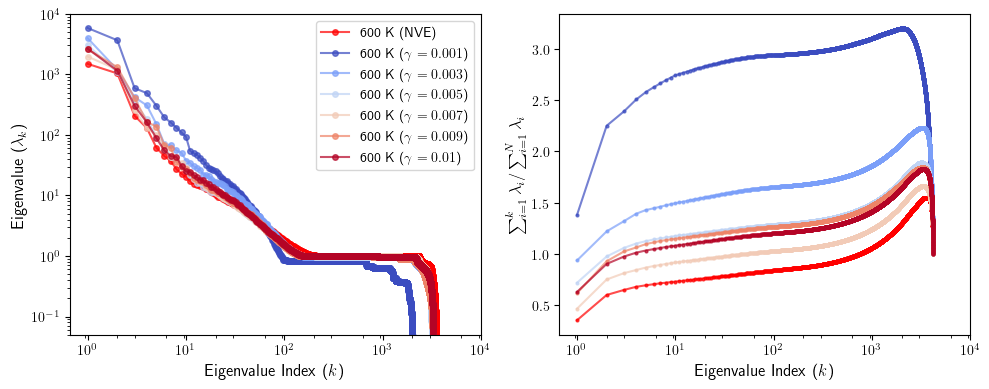

In [16]:
covariance_matrix_600K = np.load(
    "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/600_K/covariance_matrix_from_averaged_structure.npy"
)
covariance_matrix_600K_lambda_0_001 = np.load(
    "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_001/covariance_matrix_from_averaged_structure.npy"
)
covariance_matrix_600K_lambda_0_003 = np.load(
    "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_003/covariance_matrix_from_averaged_structure.npy"
)
covariance_matrix_600K_lambda_0_005 = np.load(
    "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_005/covariance_matrix_from_averaged_structure.npy"
)   
covariance_matrix_600K_lambda_0_007 = np.load(
    "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_007/covariance_matrix_from_averaged_structure.npy"
)
covariance_matrix_600K_lambda_0_009 = np.load(
    "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_009/covariance_matrix_from_averaged_structure.npy"
)   
covariance_matrix_600K_lambda_0_01 = np.load(
    "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/langevin_md/FT_MACE_long_traj/600_K_gamma_0_01/covariance_matrix_from_averaged_structure.npy"
)

element = "Li"
input_atom_order = read("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/600_K/CONTCAR").get_chemical_symbols()
element_indices = [i for i, symbol in enumerate(input_atom_order) if symbol == element]
covariance_matrix_600K_element = covariance_matrix_600K[np.ix_(element_indices * 3, element_indices * 3)]
covariance_matrix_600K_lambda_0_001_element = covariance_matrix_600K_lambda_0_001[np.ix_(element_indices * 3, element_indices * 3)]
covariance_matrix_600K_lambda_0_003_element = covariance_matrix_600K_lambda_0_003[np.ix_(element_indices * 3, element_indices * 3)]
covariance_matrix_600K_lambda_0_005_element = covariance_matrix_600K_lambda_0_005[np.ix_(element_indices * 3, element_indices * 3)]
covariance_matrix_600K_lambda_0_007_element = covariance_matrix_600K_lambda_0_007[np.ix_(element_indices * 3, element_indices * 3)]
covariance_matrix_600K_lambda_0_009_element = covariance_matrix_600K_lambda_0_009[np.ix_(element_indices * 3, element_indices * 3)]
covariance_matrix_600K_lambda_0_01_element = covariance_matrix_600K_lambda_0_01[np.ix_(element_indices * 3, element_indices * 3)]

eigenvalues_600K, eigenvectors_600K = np.linalg.eigh(covariance_matrix_600K)
eigenvalues_600K_lambda_0_001, eigenvectors_600K_lambda_0_001 = np.linalg.eigh(covariance_matrix_600K_lambda_0_001)
eigenvalues_600K_lambda_0_003, eigenvectors_600K_lambda_0_003 = np.linalg.eigh(covariance_matrix_600K_lambda_0_003)
eigenvalues_600K_lambda_0_005, eigenvectors_600K_lambda_0_005 = np.linalg.eigh(covariance_matrix_600K_lambda_0_005)
eigenvalues_600K_lambda_0_007, eigenvectors_600K_lambda_0_007 = np.linalg.eigh(covariance_matrix_600K_lambda_0_007)
eigenvalues_600K_lambda_0_009, eigenvectors_600K_lambda_0_009 = np.linalg.eigh(covariance_matrix_600K_lambda_0_009)
eigenvalues_600K_lambda_0_01, eigenvectors_600K_lambda_0_01 = np.linalg.eigh(covariance_matrix_600K_lambda_0_01)

eigenvalues_600K_element, eigenvectors_600K_element = np.linalg.eigh(covariance_matrix_600K_element)
eigenvalues_600K_lambda_0_001_element, eigenvectors_600K_lambda_0_001_element = np.linalg.eigh(covariance_matrix_600K_lambda_0_001_element)
eigenvalues_600K_lambda_0_003_element, eigenvectors_600K_lambda_0_003_element = np.linalg.eigh(covariance_matrix_600K_lambda_0_003_element)
eigenvalues_600K_lambda_0_005_element, eigenvectors_600K_lambda_0_005_element = np.linalg.eigh(covariance_matrix_600K_lambda_0_005_element)
eigenvalues_600K_lambda_0_007_element, eigenvectors_600K_lambda_0_007_element = np.linalg.eigh(covariance_matrix_600K_lambda_0_007_element)
eigenvalues_600K_lambda_0_009_element, eigenvectors_600K_lambda_0_009_element = np.linalg.eigh(covariance_matrix_600K_lambda_0_009_element)
eigenvalues_600K_lambda_0_01_element, eigenvectors_600K_lambda_0_01_element = np.linalg.eigh(covariance_matrix_600K_lambda_0_01_element)

eigenvalues_600K = eigenvalues_600K[np.argsort(eigenvalues_600K)[::-1]]
eigenvalues_600K_lambda_0_001 = eigenvalues_600K_lambda_0_001[np.argsort(eigenvalues_600K_lambda_0_001)[::-1]]
eigenvalues_600K_lambda_0_003 = eigenvalues_600K_lambda_0_003[np.argsort(eigenvalues_600K_lambda_0_003)[::-1]]
eigenvalues_600K_lambda_0_005 = eigenvalues_600K_lambda_0_005[np.argsort(eigenvalues_600K_lambda_0_005)[::-1]]
eigenvalues_600K_lambda_0_007 = eigenvalues_600K_lambda_0_007[np.argsort(eigenvalues_600K_lambda_0_007)[::-1]]
eigenvalues_600K_lambda_0_009 = eigenvalues_600K_lambda_0_009[np.argsort(eigenvalues_600K_lambda_0_009)[::-1]]
eigenvalues_600K_lambda_0_01 = eigenvalues_600K_lambda_0_01[np.argsort(eigenvalues_600K_lambda_0_01)[::-1]]

eigenvalues_600K_element = eigenvalues_600K_element[np.argsort(eigenvalues_600K_element)[::-1]]
eigenvalues_600K_lambda_0_001_element = eigenvalues_600K_lambda_0_001_element[np.argsort(eigenvalues_600K_lambda_0_001_element)[::-1]]
eigenvalues_600K_lambda_0_003_element = eigenvalues_600K_lambda_0_003_element[np.argsort(eigenvalues_600K_lambda_0_003_element)[::-1]]
eigenvalues_600K_lambda_0_005_element = eigenvalues_600K_lambda_0_005_element[np.argsort(eigenvalues_600K_lambda_0_005_element)[::-1]]
eigenvalues_600K_lambda_0_007_element = eigenvalues_600K_lambda_0_007_element[np.argsort(eigenvalues_600K_lambda_0_007_element)[::-1]]
eigenvalues_600K_lambda_0_009_element = eigenvalues_600K_lambda_0_009_element[np.argsort(eigenvalues_600K_lambda_0_009_element)[::-1]]
eigenvalues_600K_lambda_0_01_element = eigenvalues_600K_lambda_0_01_element[np.argsort(eigenvalues_600K_lambda_0_01_element)[::-1]] 

colors = plt.cm.coolwarm(np.linspace(0, 1, 6))
color_600K = 'r'
color_600K_lambda_0_001 = colors[0]
color_600K_lambda_0_003 = colors[1]
color_600K_lambda_0_005 = colors[2]
color_600K_lambda_0_007 = colors[3]
color_600K_lambda_0_009 = colors[4]
color_600K_lambda_0_01 = colors[5]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot([i + 1 for i in range(len(eigenvalues_600K))], eigenvalues_600K, "o-", c=color_600K, label="600 K (NVE)", alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_001))], eigenvalues_600K_lambda_0_001, "o-", label="600 K ($\\gamma=0.001$)", c=color_600K_lambda_0_001, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_003))], eigenvalues_600K_lambda_0_003, "o-", label="600 K ($\\gamma=0.003$)", c=color_600K_lambda_0_003, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_005))], eigenvalues_600K_lambda_0_005, "o-", label="600 K ($\\gamma=0.005$)", c=color_600K_lambda_0_005, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_007))], eigenvalues_600K_lambda_0_007, "o-", label="600 K ($\\gamma=0.007$)", c=color_600K_lambda_0_007, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_009))], eigenvalues_600K_lambda_0_009, "o-", label="600 K ($\\gamma=0.009$)", c=color_600K_lambda_0_009, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_01))], eigenvalues_600K_lambda_0_01, "o-", label="600 K ($\\gamma=0.01$)", c=color_600K_lambda_0_01, alpha=0.7,markersize=4)

"""
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_element))], eigenvalues_600K_element, "o-", c=color_600K, label="600 K (NVE, Li)", alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_001_element))], eigenvalues_600K_lambda_0_001_element, "o-", label="600 K ($\\gamma=0.001$, Li)", c=color_600K_lambda_0_001, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_003_element))], eigenvalues_600K_lambda_0_003_element, "o-", label="600 K ($\\gamma=0.003$, Li)", c=color_600K_lambda_0_003, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_005_element))], eigenvalues_600K_lambda_0_005_element, "o-", label="600 K ($\\gamma=0.005$, Li)", c=color_600K_lambda_0_005, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_007_element))], eigenvalues_600K_lambda_0_007_element, "o-", label="600 K ($\\gamma=0.007$, Li)", c=color_600K_lambda_0_007, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_009_element))], eigenvalues_600K_lambda_0_009_element, "o-", label="600 K ($\\gamma=0.009$, Li)", c=color_600K_lambda_0_009, alpha=0.7,markersize=4)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_01_element))], eigenvalues_600K_lambda_0_01_element, "o-", label="600 K ($\\gamma=0.01$, Li)", c=color_600K_lambda_0_01, alpha=0.7,markersize=4)
"""
"""
ax[0].plot([i+1 for i in range(len(eigenvalues_600K))], eigenvalues_600K,'--', c='k', label="total")
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_001))], eigenvalues_600K_lambda_0_001, "--", c="k")
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_003))], eigenvalues_600K_lambda_0_003, "--", c="k")
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_005))], eigenvalues_600K_lambda_0_005, "--", c="k")
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_007))], eigenvalues_600K_lambda_0_007, "--", c="k")
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_009))], eigenvalues_600K_lambda_0_009, "--", c="k")
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_01))], eigenvalues_600K_lambda_0_01, "--", c="k")
"""

ax[0].set_yscale("log")
ax[0].set_ylim(5e-2, 1e4)
ax[0].set_xscale("log", base=np.sqrt(10))
ax[0].set_xticks([1, 10, 100, 1000, 10000], labels=["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$10^4$"])
ax[0].set_xlabel("Eigenvalue Index ($k$)", fontsize=12)
ax[0].set_ylabel("Eigenvalue ($\\lambda_k$)", fontsize=12)
ax[0].tick_params(axis="both", which="both", labelsize=10)
ax[0].legend(fontsize=10)


ax[1].plot([i + 1 for i in range(len(eigenvalues_600K))],[np.sum(eigenvalues_600K[: i + 1]) / np.sum(eigenvalues_600K) for i in range(len(eigenvalues_600K))],"o-",c=color_600K,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_001))],[np.sum(eigenvalues_600K_lambda_0_001[: i + 1]) / np.sum(eigenvalues_600K_lambda_0_001) for i in range(len(eigenvalues_600K_lambda_0_001))],"o-",c=color_600K_lambda_0_001,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_003))],[np.sum(eigenvalues_600K_lambda_0_003[: i + 1]) / np.sum(eigenvalues_600K_lambda_0_003) for i in range(len(eigenvalues_600K_lambda_0_003))],"o-",c=color_600K_lambda_0_003,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_005))],[np.sum(eigenvalues_600K_lambda_0_005[: i + 1]) / np.sum(eigenvalues_600K_lambda_0_005) for i in range(len(eigenvalues_600K_lambda_0_005))],"o-",c=color_600K_lambda_0_005,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_007))],[np.sum(eigenvalues_600K_lambda_0_007[: i + 1]) / np.sum(eigenvalues_600K_lambda_0_007) for i in range(len(eigenvalues_600K_lambda_0_007))],"o-",c=color_600K_lambda_0_007,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_009))],[np.sum(eigenvalues_600K_lambda_0_009[: i + 1]) / np.sum(eigenvalues_600K_lambda_0_009) for i in range(len(eigenvalues_600K_lambda_0_009))],"o-",c=color_600K_lambda_0_009,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_600K_lambda_0_01))],[np.sum(eigenvalues_600K_lambda_0_01[: i + 1]) / np.sum(eigenvalues_600K_lambda_0_01) for i in range(len(eigenvalues_600K_lambda_0_01))],"o-",c=color_600K_lambda_0_01,alpha=0.7,markersize=2)

ax[1].set_xscale("log", base=np.sqrt(10))
ax[1].set_xticks([1, 10, 100, 1000, 10000], labels=["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$10^4$"])
ax[1].set_xlabel("Eigenvalue Index ($k$)", fontsize=12)
ax[1].set_ylabel("$\\sum_{i=1}^k \\lambda_i / \\sum_{i=1}^N \\lambda_i$", fontsize=12)
ax[1].tick_params(axis="both", which="both", labelsize=10)

plt.tight_layout()
plt.show()